<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/07_temporal_domain_adaptation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 07 · Temporal domain adaptation

**Question:** can we retain historical fraud examples while giving more emphasis to historical applications that resemble the latest observed population?

Stage A compared training-set composition. This experiment instead changes **sample weights**, using a period classifier fitted without fraud labels. It is a bounded follow-up, not evidence that drift adaptation necessarily helps.

- **Fraud training:** months 0–4, with the same 10:1 random undersamples as Stage C1.
- **Auxiliary task:** distinguish months 0–3 (source) from month 4 (recent reference).
- **Evaluation:** month 5 only. Months 6–7 are excluded when loading data.
- **Main model:** the previously selected CatBoost configuration, fixed in advance.
- **Conditions:** unweighted, mild adaptation, stronger adaptation; seeds 42/43/44.
- **Selection:** validation average precision (AP); report recall at 5% FPR and review budgets as secondary outcomes.

The reference population is **last month's population**, not the unseen future month. We assume it is a useful proxy for month 5. This is a strict future-prediction experiment, not target-batch adaptation.

Run cells from top to bottom. No earlier model notebook needs to be rerun; only the prepared parquet/manifest pair is required. Full-data experiment results are intentionally blank until you run this notebook.


## 1. Paths

**Colab:** use `MyDrive/BT4012_grp_proj/processed/baf_clean.parquet` and `preparation_manifest.json` from data preparation. Raw `Base.csv` is not read here.

**Local:** put this notebook under `notebooks/` and the prepared pair under `data/processed/`. Set `LOCAL_REPO_ROOT` if automatic detection cannot locate the repository.

Each execution creates separate results and artifact folders; it does not overwrite earlier experiments.


In [2]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 2. Dependencies and fixed configuration

Locally install `numpy pandas scikit-learn matplotlib joblib pyarrow catboost ipython` into the notebook kernel's environment. Colab installs missing packages automatically. Package versions are recorded with the run.

The domain classifier uses three stratified folds and a small fixed CatBoost model. Its settings are not selected using month-5 performance. The three fraud-model seeds share the same domain weights; their spread measures sampling/model variability conditional on this weight estimate, not all adaptation uncertainty.


In [3]:
import importlib.util
import subprocess

required_packages = {
    'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn',
    'matplotlib': 'matplotlib', 'joblib': 'joblib',
    'pyarrow': 'pyarrow>=14', 'catboost': 'catboost>=1.2',
}
missing = [package for module, package in required_packages.items()
           if importlib.util.find_spec(module) is None]

if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    else:
        raise ImportError('Install into this kernel: python -m pip install ' + ' '.join(missing))

import hashlib
import json
import platform
import time
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import catboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, brier_score_loss

SEEDS = [42, 43, 44]
N_JOBS = 2
VERIFY_CHECKSUM = True
SAVE_MODELS = True
SAVE_PREDICTIONS = True
TRAIN_MONTHS = [0, 1, 2, 3, 4]
VALIDATION_MONTHS = [5]
SOURCE_MONTHS = [0, 1, 2, 3]
REFERENCE_MONTH = 4
NEGATIVES_PER_POSITIVE = 10
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]

DOMAIN_SEED = 2026
DOMAIN_FOLDS = 3
DOMAIN_PARAMS = {'iterations': 200, 'depth': 4}
FRAUD_PARAMS = {'iterations': 600, 'depth': 4}
CONDITIONS = {'unweighted': 0.0, 'mild': 0.5, 'stronger': 1.0}
RATIO_LIMITS = (0.2, 5.0)

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RUN_NAME = 'temporal_domain_adaptation_' + run_id
RESULTS_DIR = PROJECT_DIR / 'results' / 'temporal_domain_adaptation' / RUN_NAME
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'temporal_domain_adaptation' / RUN_NAME
FIGURES_DIR = RESULTS_DIR / 'figures'

for directory in [RESULTS_DIR, ARTIFACTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200})
print('Results:', RESULTS_DIR)
print('Artifacts:', ARTIFACTS_DIR)
print('Planned fits: 3 period-classifier folds + 9 fraud models.')


Results: /content/drive/MyDrive/BT4012_grp_proj/results/temporal_domain_adaptation/temporal_domain_adaptation_20261117T151240Z_2f93c8
Artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/temporal_domain_adaptation/temporal_domain_adaptation_20261117T151240Z_2f93c8
Planned fits: 3 period-classifier folds + 9 fraud models.


## 3. Load development data and verify preparation

Reuse the manifest's exact feature order, missing-value handling and constant-column exclusions. The checksum verifies file provenance; the parquet filter excludes test rows from the analysis. No month, target or row identifier can enter either model.


In [4]:
def file_sha256(path):
    """Return a chunked SHA-256 digest to verify the prepared file matches its manifest."""
    digest = hashlib.sha256()

    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run 00_data_preparation.ipynb first with the same project paths.')

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)

if manifest.get('schema_version') != 1:
    raise ValueError('Unsupported preparation manifest version.')

if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Parquet fingerprint differs from the manifest; rerun preparation.')


TARGET = manifest['target']
MONTH = manifest['month_column']
ROW_ID = manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL = manifest['numerical_features']
CATEGORICAL = manifest['categorical_features']

if manifest['split_months']['train'] != TRAIN_MONTHS:
    raise ValueError('This experiment expects training months 0–4.')

if manifest['split_months']['validation'] != VALIDATION_MONTHS:
    raise ValueError('This experiment expects validation month 5.')

if set(FEATURES) != set(NUMERICAL + CATEGORICAL):
    raise ValueError('Inconsistent feature lists in preparation manifest.')

if set(FEATURES) & {TARGET, MONTH, ROW_ID}:
    raise ValueError('Target, month or row ID cannot be predictors.')

df = pd.read_parquet(
    CLEAN_PATH,
    filters=[(MONTH, 'in', TRAIN_MONTHS + VALIDATION_MONTHS)],
)

if list(df.columns) != manifest['columns'] or not df[ROW_ID].is_unique:
    raise ValueError('Prepared schema or row identifiers are inconsistent.')

for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

# Sort by original row ID to make sampling reproducible if parquet row order changes.
history = df[df[MONTH].isin(TRAIN_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
validation = df[df[MONTH].isin(VALIDATION_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
del df

for name, frame in [('train', history), ('validation', validation)]:
    if len(frame) != manifest['split_counts'][name]:
        raise ValueError(f'{name} row count differs from the preparation manifest.')

    if not frame[TARGET].isin([0, 1]).all() or frame[TARGET].nunique() != 2:
        raise ValueError(f'{name} must contain valid labels and both classes.')

X_validation = validation[FEATURES]
y_validation = validation[TARGET].to_numpy()
validation_ties = np.random.default_rng(2026).random(len(validation))

display(history.groupby(MONTH)[TARGET].agg(
    applications='size', frauds='sum', fraud_rate='mean',
))
print('Validation applications:', len(validation))
print('Validation frauds:', int(y_validation.sum()))
print('Predictors:', len(FEATURES))


,applications,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371


Validation applications: 119323
Validation frauds: 1411
Predictors: 29


## 4. Shared model and evaluation helpers

The fraud-model factory matches Stage C1: numeric missing values remain native, categorical missing values receive a fixed token, and CatBoost uses 600 trees, depth 4, learning rate 0.05 and L2 regularisation 3. No early stopping or extra class weights are added.

**Recall at 5% FPR** is a validation ranking benchmark using validation labels to select the empirical cutoff. Saving that cutoff does not guarantee 5% FPR in future months. Review-capacity metrics select an exact number of applications with label-independent tie breaking.


In [5]:
def make_catboost(params, seed):
    """Build the same preprocessing and CatBoost setup used in Stage C1."""
    preprocessing = ColumnTransformer([
        ('numeric', 'passthrough', NUMERICAL),
        ('categorical', SimpleImputer(
            strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
        ), CATEGORICAL),
    ])

    classifier = CatBoostClassifier(
        loss_function='Logloss', iterations=params['iterations'], depth=params['depth'],
        learning_rate=0.05, l2_leaf_reg=3.0, boosting_type='Plain', task_type='CPU',
        cat_features=list(range(len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL))),
        random_seed=seed, thread_count=N_JOBS, verbose=False, allow_writing_files=False,
    )

    return Pipeline([('preprocessing', preprocessing), ('classifier', classifier)])


def json_safe(value):
    """Convert NumPy values and nonfinite floats to portable JSON values."""
    if isinstance(value, dict):
        return {k: json_safe(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    if isinstance(value, np.generic):
        return value.item()
    return value


def write_json(name, payload):
    """Write run metadata without nonstandard NaN/Infinity JSON literals."""
    (RESULTS_DIR / name).write_text(json.dumps(json_safe(payload), indent=2, allow_nan=False))


def effective_sample_size(weights):
    """Kish ESS measures weight concentration, not independent fraud information."""
    weights = np.asarray(weights, dtype=float)
    return float(weights.sum() ** 2 / np.square(weights).sum())


In [6]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


## 5. Estimate relevance with out-of-fold period predictions

Let D=0 denote months 0–3 and D=1 denote month 4. The period classifier estimates q(x)=P(D=1|x). Convert its odds to a density-ratio estimate:

\[
 r(x) = \frac{q(x)}{1-q(x)}\frac{n_{source}}{n_{reference}}.
\]

The sample-count factor corrects the domain class prior. Use each fold's training counts, not an assumed 50:50 prior. Fit on the **natural application population before fraud undersampling**. Domain folds are stratified only by period, and every row receives a prediction from a model that did not train on that row.

Random domain folds are appropriate for estimating these two already-observed populations; they are not a fraud backtest. Fraud labels and month-5 features do not enter this step. Month 4 remains labelled fraud training data later—we simply ignore those labels when learning population similarity.

A strong domain AUC indicates distinguishable populations, not successful fraud adaptation. Ratios also depend on probability quality, so record out-of-fold Brier score and reliability bins. There is no post-hoc domain calibration search in this bounded experiment.


In [7]:
source_mask = history[MONTH].isin(SOURCE_MONTHS).to_numpy()
reference_mask = history[MONTH].eq(REFERENCE_MONTH).to_numpy()
assert np.all(source_mask | reference_mask) and not np.any(source_mask & reference_mask)

domain_y = reference_mask.astype(int)
X_domain = history[FEATURES]
domain_probability = np.full(len(history), np.nan)
density_ratio = np.full(len(history), np.nan)
domain_fold = np.full(len(history), -1, dtype=int)
fold_metrics, importance_rows = [], []

splitter = StratifiedKFold(n_splits=DOMAIN_FOLDS, shuffle=True, random_state=DOMAIN_SEED)
for fold, (fit_idx, holdout_idx) in enumerate(splitter.split(X_domain, domain_y)):
    started = time.perf_counter()
    domain_model = make_catboost(DOMAIN_PARAMS, DOMAIN_SEED + fold)
    domain_model.fit(X_domain.iloc[fit_idx], domain_y[fit_idx])
    q = domain_model.predict_proba(X_domain.iloc[holdout_idx])[:, 1]

    # Epsilon only prevents numerical infinities; substantive clipping happens below.
    q_safe = np.clip(q, 1e-6, 1 - 1e-6)
    n_source = int((domain_y[fit_idx] == 0).sum())
    n_reference = int((domain_y[fit_idx] == 1).sum())
    domain_probability[holdout_idx] = q
    density_ratio[holdout_idx] = q_safe / (1 - q_safe) * n_source / n_reference
    domain_fold[holdout_idx] = fold

    fold_metrics.append({
        'fold': fold, 'source_fit_rows': n_source, 'reference_fit_rows': n_reference,
        'auc': roc_auc_score(domain_y[holdout_idx], q),
        'brier': brier_score_loss(domain_y[holdout_idx], q),
        'seconds': time.perf_counter() - started,
    })
    # The transformer orders numeric columns before categorical columns.
    importance_rows.append(pd.Series(
        domain_model.named_steps['classifier'].feature_importances_,
        index=NUMERICAL + CATEGORICAL, name=f'fold_{fold}',
    ))
    if SAVE_MODELS:
        joblib.dump(domain_model, ARTIFACTS_DIR / f'domain_fold_{fold}.joblib', compress=3)
    print(f"Domain fold {fold + 1}/{DOMAIN_FOLDS}: AUC={fold_metrics[-1]['auc']:.4f}")

assert np.isfinite(domain_probability).all() and np.isfinite(density_ratio).all()
assert (domain_fold >= 0).all() and (density_ratio > 0).all()
domain_results = pd.DataFrame(fold_metrics)
domain_results.to_csv(RESULTS_DIR / 'domain_fold_metrics.csv', index=False)
display(domain_results)

importance = pd.concat(importance_rows, axis=1)
importance['mean_importance'] = importance.mean(axis=1)
importance = importance.sort_values('mean_importance', ascending=False)
importance.to_csv(RESULTS_DIR / 'domain_feature_importance.csv', index_label='feature')
display(importance.head(12))

reliability = pd.DataFrame({'q': domain_probability, 'actual_recent': domain_y})
reliability['bin'] = pd.cut(reliability.q, np.linspace(0, 1, 11), include_lowest=True)
reliability = reliability.groupby('bin', observed=True).agg(
    rows=('q', 'size'), mean_predicted=('q', 'mean'), recent_fraction=('actual_recent', 'mean'),
).reset_index()
reliability.to_csv(RESULTS_DIR / 'domain_reliability.csv', index=False)
display(reliability)


Domain fold 1/3: AUC=0.9093
Domain fold 2/3: AUC=0.9074
Domain fold 3/3: AUC=0.9092


,fold,source_fit_rows,reference_fit_rows,auc,brier,seconds
0,0,365316,85128,0.909332,0.088477,114.595875
1,1,365317,85127,0.907448,0.089565,103.938430
2,2,365317,85127,0.909200,0.088388,100.928671


,fold_0,fold_1,fold_2,mean_importance
velocity_4w,84.339066,83.841075,84.958614,84.379585
velocity_24h,6.556544,7.144151,6.587451,6.762716
velocity_6h,2.958157,2.797873,2.614358,2.790129
date_of_birth_distinct_emails_4w,1.015285,1.084973,1.113927,1.071395
intended_balcon_amount,0.874716,1.043244,0.709821,0.875927
keep_alive_session,0.928516,0.717487,0.708396,0.784800
email_is_free,0.434735,0.572920,0.480500,0.496052
customer_age,0.454745,0.439275,0.361752,0.418590
proposed_credit_limit,0.387310,0.443316,0.399683,0.410103
housing_status,0.429603,0.360944,0.337901,0.376150


,bin,rows,mean_predicted,recent_fraction
0,"(-0.001, 0.1]",392440,0.020993,0.020717
1,"(0.1, 0.2]",45727,0.150946,0.132394
2,"(0.2, 0.3]",60740,0.252070,0.232614
3,"(0.3, 0.4]",60740,0.347812,0.348370
4,"(0.4, 0.5]",34063,0.442119,0.469395
5,"(0.5, 0.6]",10865,0.542113,0.570916
6,"(0.6, 0.7]",11815,0.657844,0.635463
7,"(0.7, 0.8]",29119,0.756266,0.761221
8,"(0.8, 0.9]",29728,0.838876,0.872443
9,"(0.9, 1.0]",429,0.907436,0.969697


## 6. Build bounded relevance weights and inspect concentration

For source rows, clip the estimated ratio to [0.2, 5], raise it to power alpha, then normalise **within the source population** to mean 1. Mild uses alpha=0.5; stronger uses alpha=1. Month-4 rows receive weight 1. This preserves the total source/reference weight balance before fraud undersampling and tests within-history relevance rather than simply boosting the recent month.

Clipping and normalisation deliberately produce a **regularised heuristic**, not exact unbiased target-risk estimation. Bounds refer to ratios before normalisation, not final weights. For each sampled fraud training set, apply one further overall mean-1 normalisation to keep weight scale comparable; do not normalise the fraud classes separately.

The weighted fraud prevalence may change. We report it because that is part of what density weighting does. Every condition still uses the identical physical rows and no additional class weighting.


,condition,month,rows,mean_weight,min_weight,max_weight,ess,ess_fraction,weighted_fraud_rate
0,unweighted,0,132440,1.000000,1.000000,1.000000,132440.000000,1.000000,0.011326
1,unweighted,1,127620,1.000000,1.000000,1.000000,127620.000000,1.000000,0.009387
2,unweighted,2,136979,1.000000,1.000000,1.000000,136979.000000,1.000000,0.008746
3,unweighted,3,150936,1.000000,1.000000,1.000000,150936.000000,1.000000,0.009222
4,unweighted,4,127691,1.000000,1.000000,1.000000,127691.000000,1.000000,0.011371
5,mild,0,132440,0.717451,0.607655,3.038275,96057.989846,0.725294,0.011845
6,mild,1,127620,0.738515,0.607655,3.038275,91779.049004,0.719159,0.010078
7,mild,2,136979,0.811616,0.607655,3.038275,97859.448656,0.714412,0.009312
8,mild,3,150936,1.639981,0.607655,3.038275,129278.124365,0.856510,0.009854
9,mild,4,127691,1.000000,1.000000,1.000000,127691.000000,1.000000,0.011371


Source ratios clipped at lower/upper bounds: 63.2% / 3.2%
Source ratio percentiles: [1.16323208e-02 1.85291811e-02 9.64199435e-02 1.50235835e+01
 4.56195480e+01]
CAUTION: substantial clipping. Interpret this as a limited-overlap stress test.


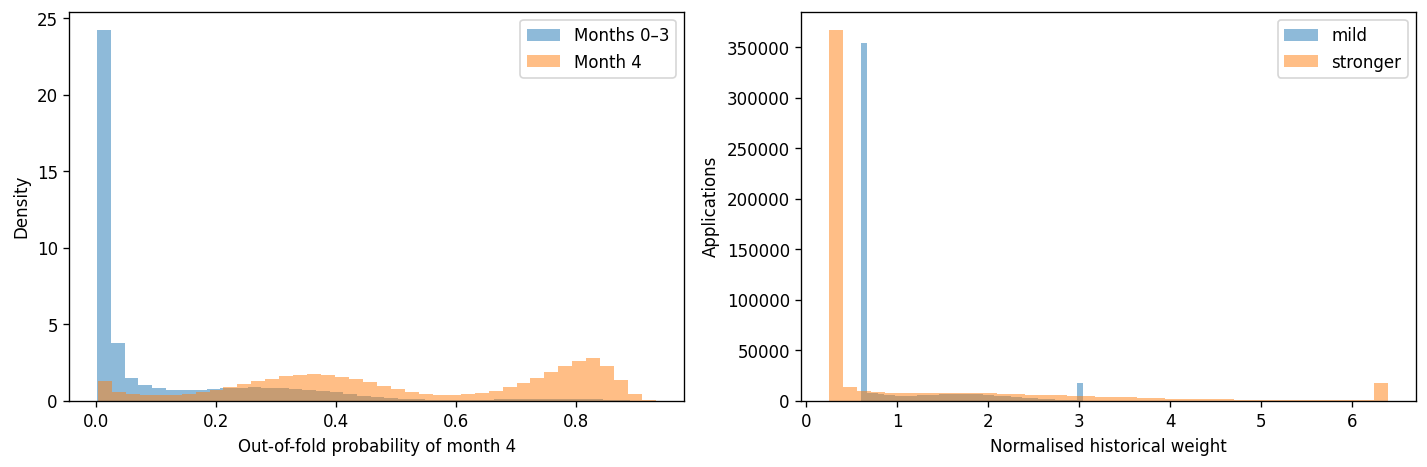

In [8]:
def build_relevance_weights(ratios, source_rows, alpha):
    """Reweight older rows; keep the recent reference at unit weight."""
    weights = np.ones(len(ratios), dtype=float)
    if alpha > 0:
        source_weights = np.clip(ratios[source_rows], *RATIO_LIMITS) ** alpha
        weights[source_rows] = source_weights / source_weights.mean()
    return weights


weights_by_condition = {
    name: build_relevance_weights(density_ratio, source_mask, alpha)
    for name, alpha in CONDITIONS.items()
}
weight_rows = []
for name, weights in weights_by_condition.items():
    assert np.isfinite(weights).all() and (weights > 0).all()
    assert np.allclose(weights[reference_mask], 1.0)
    for month in TRAIN_MONTHS:
        mask = history[MONTH].eq(month).to_numpy()
        w = weights[mask]
        labels = history.loc[mask, TARGET].to_numpy()
        weight_rows.append({
            'condition': name, 'month': month, 'rows': len(w),
            'mean_weight': w.mean(), 'min_weight': w.min(), 'max_weight': w.max(),
            'ess': effective_sample_size(w), 'ess_fraction': effective_sample_size(w) / len(w),
            'weighted_fraud_rate': np.average(labels, weights=w),
        })

weight_diagnostics = pd.DataFrame(weight_rows)
weight_diagnostics.to_csv(RESULTS_DIR / 'weights_by_month.csv', index=False)
display(weight_diagnostics)

clip_low = float((density_ratio[source_mask] < RATIO_LIMITS[0]).mean())
clip_high = float((density_ratio[source_mask] > RATIO_LIMITS[1]).mean())
print(f'Source ratios clipped at lower/upper bounds: {clip_low:.1%} / {clip_high:.1%}')
print('Source ratio percentiles:', np.quantile(density_ratio[source_mask], [0, .01, .5, .99, 1]))
if clip_low + clip_high > 0.25:
    print('CAUTION: substantial clipping. Interpret this as a limited-overlap stress test.')

weight_artifact = history[[ROW_ID, MONTH]].copy()
weight_artifact['domain_fold'] = domain_fold
weight_artifact['oof_recent_probability'] = domain_probability
weight_artifact['estimated_density_ratio'] = density_ratio
for name, weights in weights_by_condition.items():
    weight_artifact['weight_' + name] = weights
weight_artifact.to_parquet(ARTIFACTS_DIR / 'domain_weights.parquet', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, mask in [('Months 0–3', source_mask), ('Month 4', reference_mask)]:
    axes[0].hist(domain_probability[mask], bins=40, density=True, alpha=.5, label=label)
axes[0].set(xlabel='Out-of-fold probability of month 4', ylabel='Density')
axes[0].legend()
for name in ['mild', 'stronger']:
    axes[1].hist(weights_by_condition[name][source_mask], bins=40, alpha=.5, label=name)
axes[1].set(xlabel='Normalised historical weight', ylabel='Applications')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'domain_weight_diagnostics.png')
plt.show()


## 7. Matched undersamples and nine fraud-model fits

Sampling uses the same seed/permutation rule as Stage C1. All frauds are retained, with ten random legitimate examples per fraud. Within each seed, only sample weights change. The unweighted condition does not pass an explicit sample-weight argument, matching the earlier control as closely as package versions allow.

Run this cell once per fresh run. Results and predictions are checkpointed after each fit. If interrupted, partial files remain for inspection; restart top-to-bottom for a new complete run rather than combining partial runs silently.


In [9]:
run_info = {
    'status': 'running', 'run_name': RUN_NAME,
    'preparation_id': manifest['preparation_id'], 'prepared_sha256': manifest['prepared_sha256'],
    'features': FEATURES, 'train_months': TRAIN_MONTHS, 'validation_months': VALIDATION_MONTHS,
    'source_months': SOURCE_MONTHS, 'reference_month': REFERENCE_MONTH,
    'seeds': SEEDS, 'domain_seed': DOMAIN_SEED, 'domain_folds': DOMAIN_FOLDS,
    'domain_params': DOMAIN_PARAMS, 'fraud_params': FRAUD_PARAMS,
    'conditions_alpha': CONDITIONS, 'ratio_clip_before_normalisation': RATIO_LIMITS,
    'negative_to_positive_ratio': NEGATIVES_PER_POSITIVE,
    'selection_metric': 'validation_average_precision',
    'domain_auc_oof': roc_auc_score(domain_y, domain_probability),
    'domain_brier_oof': brier_score_loss(domain_y, domain_probability),
    'source_clip_low_fraction': clip_low, 'source_clip_high_fraction': clip_high,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'catboost': catboost.__version__},
}
write_json('run_manifest.json', run_info)

positive_positions = np.flatnonzero(history[TARGET].to_numpy() == 1)
negative_positions = np.flatnonzero(history[TARGET].to_numpy() == 0)
n_negative = NEGATIVES_PER_POSITIVE * len(positive_positions)
assert n_negative <= len(negative_positions)
metric_rows, capacity_rows = [], []

for seed in SEEDS:
    negative_order = np.random.default_rng(seed).permutation(negative_positions)
    selected = np.concatenate([positive_positions, negative_order[:n_negative]])
    subset = history.iloc[selected].sort_values(ROW_ID)
    positions = subset.index.to_numpy()
    y_fit = subset[TARGET].to_numpy()
    ids = subset[ROW_ID].to_numpy(dtype=np.int64)
    row_digest = hashlib.sha256(ids.astype('<i8').tobytes()).hexdigest()
    subset[[ROW_ID]].to_parquet(ARTIFACTS_DIR / f'train_ids_seed_{seed}.parquet', index=False)

    for condition in CONDITIONS:
        weights = weights_by_condition[condition][positions].copy()
        weights /= weights.mean()
        model = make_catboost(FRAUD_PARAMS, seed)
        fit_kwargs = {} if condition == 'unweighted' else {'classifier__sample_weight': weights}

        started = time.perf_counter()
        model.fit(subset[FEATURES], y_fit, **fit_kwargs)
        fit_seconds = time.perf_counter() - started
        scores = model.predict_proba(X_validation)[:, 1]
        assert np.isfinite(scores).all()

        threshold = threshold_for_fpr(y_validation, scores, FPR_TARGET)
        operating = at_threshold(y_validation, scores, threshold)
        tag = f'{condition}_seed_{seed}'
        metric_rows.append({
            'condition': condition, 'seed': seed, 'n_train': len(subset),
            'train_row_sha256': row_digest, 'fit_seconds': fit_seconds,
            'weighted_train_fraud_rate': np.average(y_fit, weights=weights),
            'train_weight_ess': effective_sample_size(weights),
            'train_weight_ess_fraction': effective_sample_size(weights) / len(weights),
            'average_precision': average_precision_score(y_validation, scores),
            'roc_auc': roc_auc_score(y_validation, scores),
            'recall_at_5fpr': operating['recall'], 'realised_validation_fpr': operating['fpr'],
            'validation_cutoff': threshold, 'precision_at_cutoff': operating['precision'],
        })
        cap = capacity_table(y_validation, scores, REVIEW_CAPACITIES, validation_ties)
        cap['condition'], cap['seed'] = condition, seed
        capacity_rows.extend(cap.to_dict('records'))

        if SAVE_PREDICTIONS:
            predictions = validation[[ROW_ID, MONTH, TARGET]].copy()
            predictions['score'] = scores
            predictions.to_parquet(ARTIFACTS_DIR / f'{tag}_validation.parquet', index=False)
        if SAVE_MODELS:
            joblib.dump(model, ARTIFACTS_DIR / f'{tag}.joblib', compress=3)

        pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'validation_metrics.csv', index=False)
        pd.DataFrame(capacity_rows).to_csv(RESULTS_DIR / 'validation_capacity.csv', index=False)
        write_json(f'{tag}_metadata.json', {
            **metric_rows[-1], 'alpha': CONDITIONS[condition], 'threshold_comparison': '>=',
            'infinite_cutoff_means_no_alerts': bool(np.isinf(threshold)),
        })
        print(f"{tag}: AP={metric_rows[-1]['average_precision']:.5f}, "
              f"recall@5%FPR={operating['recall']:.3%}, fit={fit_seconds:.1f}s")


unweighted_seed_42: AP=0.19725, recall@5%FPR=54.571%, fit=51.9s
mild_seed_42: AP=0.19418, recall@5%FPR=54.359%, fit=55.4s
stronger_seed_42: AP=0.18648, recall@5%FPR=53.721%, fit=56.9s
unweighted_seed_43: AP=0.19626, recall@5%FPR=54.784%, fit=51.5s
mild_seed_43: AP=0.19477, recall@5%FPR=54.571%, fit=56.2s
stronger_seed_43: AP=0.18720, recall@5%FPR=53.792%, fit=56.7s
unweighted_seed_44: AP=0.19461, recall@5%FPR=54.429%, fit=52.5s
mild_seed_44: AP=0.19457, recall@5%FPR=54.288%, fit=55.0s
stronger_seed_44: AP=0.19170, recall@5%FPR=54.288%, fit=57.5s


## 8. Paired results and decision

Compare each adapted fit with the **same-seed control**, not a previous run with potentially different versions. Seed standard deviations are descriptive, not confidence intervals. Validation has already supported several project decisions, so small gains warrant caution.

AP remains the predeclared selection metric. Report disagreements with recall and review capacity honestly. If adaptation brings negligible or inconsistent gains, retain the simpler unweighted model. Do not start repeatedly changing feature subsets, clipping bounds and reference months to chase month-5 performance.


,ap_mean,ap_std,recall_mean,recall_std,fit_seconds_mean,ess_fraction_mean
condition,,,,,,
unweighted,0.196041,0.001335,0.545948,0.001784,51.943451,1.000000
mild,0.194506,0.000299,0.544059,0.001475,55.548553,0.735437
stronger,0.188460,0.002831,0.539334,0.003089,57.016934,0.369574


,condition,seed,ap_gain,recall_gain
1,mild,42,-0.003071,-0.002126
2,stronger,42,-0.010772,-0.008505
4,mild,43,-0.001492,-0.002126
5,stronger,43,-0.009062,-0.009922
7,mild,44,-0.000042,-0.001417
8,stronger,44,-0.002907,-0.001417


precision_mean  recall_mean  frauds_flagged_mean  \
condition  capacity                                                     
mild       0.01            0.290305     0.245452           346.333333   
           0.02            0.206762     0.349634           493.333333   
           0.05            0.122863     0.519490           733.000000   
stronger   0.01            0.283319     0.239546           338.000000   
           0.02            0.203409     0.343964           485.333333   
           0.05            0.121913     0.515474           727.333333   
unweighted 0.01            0.291981     0.246870           348.333333   
           0.02            0.206482     0.349161           492.666667   
           0.05            0.123645     0.522797           737.666667   

                     legitimate_reviewed_mean  frauds_per_10000_mean  \
condition  capacity                                                    
mild       0.01                    846.666667              29.024860   
           0.02                   1892.666667              41.344362   
           0.05                   5233.000000              61.429900   
stronger   0.01                    855.000000              28.326475   
           0.02                   1900.666667              40.673913   
           0.05                   5238.666667              60.954999   
unweighted 0.01                    844.666667              29.192472   
           0.02                   1893.333333              41.288491   
           0.05                   5228.333333              61.820996   

                     legitimate_reviews_per_10000_mean  
condition  capacity                                     
mild       0.01                              70.955865  
           0.02                             158.617087  
           0.05                             438.557529  
stronger   0.01                              71.654249  
           0.02                             159.287536  
           0.05                             439.032430  
unweighted 0.01                              70.788253  
           0.02                             158.672958  
           0.05                             438.166433

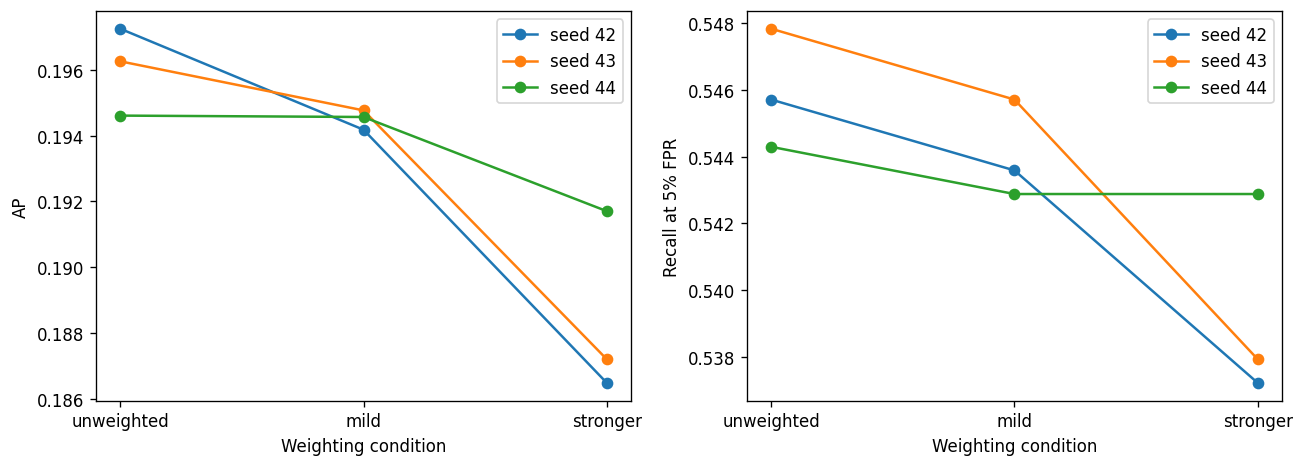

Highest mean validation AP: unweighted
Results saved to: /content/drive/MyDrive/BT4012_grp_proj/results/temporal_domain_adaptation/temporal_domain_adaptation_20261117T151240Z_2f93c8


In [10]:
metrics = pd.DataFrame(metric_rows)
assert len(metrics) == len(SEEDS) * len(CONDITIONS)
assert metrics.groupby('seed').train_row_sha256.nunique().eq(1).all()

summary = metrics.groupby('condition', sort=False).agg(
    ap_mean=('average_precision', 'mean'), ap_std=('average_precision', 'std'),
    recall_mean=('recall_at_5fpr', 'mean'), recall_std=('recall_at_5fpr', 'std'),
    fit_seconds_mean=('fit_seconds', 'mean'),
    ess_fraction_mean=('train_weight_ess_fraction', 'mean'),
)
summary.to_csv(RESULTS_DIR / 'validation_summary.csv')
display(summary)

control = metrics[metrics.condition.eq('unweighted')].set_index('seed')
paired = metrics[~metrics.condition.eq('unweighted')].copy()
paired['ap_gain'] = paired.average_precision - paired.seed.map(control.average_precision)
paired['recall_gain'] = paired.recall_at_5fpr - paired.seed.map(control.recall_at_5fpr)
paired[['condition', 'seed', 'ap_gain', 'recall_gain']].to_csv(
    RESULTS_DIR / 'paired_gains.csv', index=False,
)
display(paired[['condition', 'seed', 'ap_gain', 'recall_gain']])

capacity_summary = pd.DataFrame(capacity_rows).groupby(['condition', 'capacity']).agg(
    precision_mean=('precision', 'mean'), recall_mean=('recall', 'mean'),
    frauds_flagged_mean=('frauds_flagged', 'mean'),
    legitimate_reviewed_mean=('legitimate_reviewed', 'mean'),
    frauds_per_10000_mean=('frauds_flagged_per_10000', 'mean'),
    legitimate_reviews_per_10000_mean=('legitimate_reviewed_per_10000', 'mean'),
)
capacity_summary.to_csv(RESULTS_DIR / 'capacity_summary.csv')
display(capacity_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, label in zip(axes, ['average_precision', 'recall_at_5fpr'], ['AP', 'Recall at 5% FPR']):
    for seed in SEEDS:
        values = metrics[metrics.seed.eq(seed)].set_index('condition').loc[list(CONDITIONS), metric]
        ax.plot(list(CONDITIONS), values, marker='o', label=f'seed {seed}')
    ax.set(ylabel=label, xlabel='Weighting condition')
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'paired_validation_comparison.png')
plt.show()

# Exact ties retain the earlier, simpler condition in the predefined order.
best_condition = summary.ap_mean.idxmax()
run_info.update({'status': 'complete', 'best_mean_ap_condition': best_condition,
                 'artifact_directory': str(ARTIFACTS_DIR)})
write_json('run_manifest.json', run_info)
print('Highest mean validation AP:', best_condition)
print('Results saved to:', RESULTS_DIR)


## 9. What to write after the run

Record:

1. Can the auxiliary classifier distinguish older applications from month 4? Which features dominate?
2. Are its probability bins reasonably reliable? How much clipping was needed?
3. How concentrated are the final training weights, and how does weighted fraud prevalence change?
4. Does adaptation improve AP consistently across the three matched seeds? Does recall at 5% FPR agree?
5. What changes at 1%, 2% and 5% review capacity? Is any gain worth the added fitting and maintenance?

**Interpretation boundaries:** this tests one regularised weighting scheme toward month 4. A negative result does not rule out every kind of domain adaptation. A positive result does not prove that importance weighting repairs concept drift: changes in fraud risk conditional on features are not generally fixed by matching feature distributions. The domain classifier does not provide causal explanations.

The unweighted model is already a previously selected configuration. Adaptation strengths are compared on the same repeatedly used validation month; record that history. Months 6–7 should not be used to revise this experiment. The wider team has already inspected test results, so do not describe the entire team's holdout as wholly unseen.

**Files to share:** notebook, `validation_summary.csv`, `paired_gains.csv`, `capacity_summary.csv`, domain diagnostics and `run_manifest.json`. Keep model binaries, prediction parquet files and row-level weights outside ordinary Git commits.

**Reading:** [BAF documentation](https://github.com/feedzai/bank-account-fraud); [Low-Dimensional Density Ratio Estimation for Covariate Shift Correction](https://proceedings.mlr.press/v89/stojanov19a.html). This notebook uses classifier-based density ratios, not a reproduction of that paper's specific algorithm.
